<b>Sensitivity analysis

The question Google asks: “How does the plan perform under different sign-up volume scenarios?” You’ll run four tests:

Stress test: run the recommended plan as-is with 15% fewer or more sign-ups </lb>
<n>Re-optimize: what should the plan be in each scenario?</n>
<n>Safety buffer: what if you staff a little above the plan? </n>
Assumption A1: uplift on the annual budget vs only the 60-day window </b>

In [17]:
import sys, math
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt

import model.simulate as sim
from model.simulate import run_plan
from model.optimize import optimize_country

plan_df = pd.read_csv("../data/processed/plan_unbuffered.csv")
countries = sorted(plan_df["country"].unique())
recommended = {c: plan_df[plan_df["country"] == c].sort_values("month")["agents"].tolist() for c in countries}
print(len(recommended), "countries loaded")

22 countries loaded


In [14]:
optimal = {c: optimize_country(c) for c in countries}

pd.DataFrame([{"country": c, "month": i + 1, "agents": a}
              for c in countries for i, a in enumerate(optimal[c])]
            ).to_csv("../data/processed/plan_unbuffered.csv", index=False)

recommended = optimal
print("Vietnam:", optimal["Vietnam"][0], "/", optimal["Vietnam"][9])

Vietnam: 77 / 107


<b>A helper that runs a set of plans for all countries</b>

In [19]:
def evaluate_all(plans, scenario):
    """Run every country's plan under one scenario and return totals."""
    net = abandoned = 0
    worst_wait = 0
    waits_over_7 = 0
    for c in countries:
        m = run_plan(c, plans[c], scenario)
        net += m["revenue"].sum() - m["cost"].sum()
        abandoned += m["abandoned"].sum()
        w = m["avg_wait_days"].max()
        worst_wait = max(worst_wait, w)
        waits_over_7 += int(w > 7)
    return {
        "scenario": scenario,
        "net_value_M": round(net / 1e6, 1),
        "abandoned": round(abandoned),
        "worst_wait_days": round(worst_wait, 1),
        "countries_with_wait_over_7_days": waits_over_7,
        "agents_jan_sep": sum(p[0] for p in plans.values()),
        "agents_oct_dec": sum(p[9] for p in plans.values()),
    }

In [11]:
test1 = pd.DataFrame([evaluate_all(recommended, s) for s in ["low", "base", "high"]])
test1

,scenario,net_value_M,abandoned,worst_wait_days,countries_with_wait_over_7_days,agents_jan_sep,agents_oct_dec
0,low,372.4,652,0.0,0,1821,2559
1,base,470.9,768,0.0,0,1821,2559
2,high,559.1,883,4.5,0,1821,2559


<b>Test 2: re-optimize for each scenario </b>

In [21]:
reopt = {}
rows = []
for s in ["low", "high"]:
    reopt[s] = {c: optimize_country(c, s) for c in countries}
    rows.append(evaluate_all(reopt[s], s))
    print("done:", s)
test2 = pd.DataFrame(rows)
test2

done: low
done: high


,scenario,net_value_M,abandoned,worst_wait_days,countries_with_wait_over_7_days,agents_jan_sep,agents_oct_dec
0,low,383.3,652,2.2,0,1395,1971
1,high,567.2,883,1.9,0,1887,2666


In [5]:
rows = []
for buffer in [0, 0.05, 0.10, 0.15]:
    buffered = {c: [math.ceil(a * (1 + buffer)) for a in recommended[c]] for c in countries}
    for s in ["low", "base", "high"]:
        r = evaluate_all(buffered, s)
        r["buffer"] = f"{buffer:.0%}"
        rows.append(r)
        
test3 = pd.DataFrame(rows).pivot(index="buffer", columns="scenario", values="net_value_M")[["low", "base", "high"]]
test3 = test3.loc[["0%", "5%", "10%", "15%"]]
test3

scenario,low,base,high
buffer,,,
0%,372.4,470.9,559.1
5%,369.8,468.3,566.8
10%,367.4,465.9,564.4
15%,365.0,463.5,562.1


In [6]:
sim.UPLIFT = 0.135 * 60 / 365          # change the assumption
plans_60day = {c: optimize_country(c) for c in countries}
test4 = evaluate_all(plans_60day, "base")
sim.UPLIFT = 0.135                      # IMPORTANT: change it back

zero_countries = [c for c, p in plans_60day.items() if p[0] == 0]
print(test4)
print("Countries that get zero agents:", zero_countries)

{'scenario': 'base', 'net_value_M': np.float64(-72.5), 'abandoned': 4061, 'worst_wait_days': np.float64(20.0), 'countries_with_wait_over_7_days': 5, 'agents_jan_sep': 1549, 'agents_oct_dec': 2096}
Countries that get zero agents: ['South Africa', 'Thailand', 'UAE']


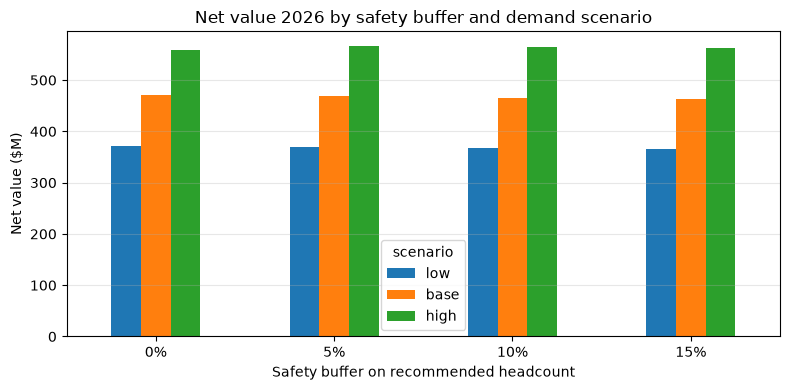

In [7]:
test3.plot(kind="bar", figsize=(8, 4))
test3 = test3.loc[["0%", "5%", "10%", "15%"]]
plt.title("Net value 2026 by safety buffer and demand scenario")
plt.ylabel("Net value ($M)")
plt.xlabel("Safety buffer on recommended headcount")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()


plt.savefig("../report/sensitivity_buffer.png", dpi=150)
plt.show()


In [8]:
test1.to_csv("../report/sensitivity_stress_test.csv", index=False)
test2.to_csv("../report/sensitivity_reoptimized.csv", index=False)
test3.to_csv("../report/sensitivity_buffer.csv")
print("Saved")

Saved


In [15]:


BUFFER = 0.10
final = {c: [math.ceil(a * (1 + BUFFER)) for a in recommended[c]] for c in countries}

In [16]:
plan_rows = [{"country": c, "month": i + 1, "agents": a}
             for c in countries for i, a in enumerate(final[c])]
pd.DataFrame(plan_rows).to_csv("../data/processed/plan.csv", index=False)

rows = []
for c in countries:
    best = run_plan(c, final[c])
    keep = run_plan(c, [int(staff[c])] * 12)
    net_best = best["revenue"].sum() - best["cost"].sum()
    net_keep = keep["revenue"].sum() - keep["cost"].sum()
    rows.append({
        "country": c, "existing": int(staff[c]),
        "base_jan_sep": final[c][0], "q4_oct_dec": final[c][9],
        "net_M": round(net_best / 1e6, 2),
        "net_keep_all_M": round(net_keep / 1e6, 2),
        "gain_M": round((net_best - net_keep) / 1e6, 2),
        "max_wait_days": round(best["avg_wait_days"].max(), 1),
        "abandoned": round(best["abandoned"].sum()),
    })
final_summary = pd.DataFrame(rows)
final_summary.to_csv("../data/processed/plan_summary.csv", index=False)

print(final_summary[["existing", "base_jan_sep", "q4_oct_dec", "net_M", "net_keep_all_M", "gain_M"]].sum())
final_summary

existing          6474.00
base_jan_sep      1821.00
q4_oct_dec        2559.00
net_M              470.93
net_keep_all_M     363.99
gain_M             106.99
dtype: float64


,country,existing,base_jan_sep,q4_oct_dec,net_M,net_keep_all_M,gain_M,max_wait_days,abandoned
0,Argentina,200,16,22,-0.65,-2.38,1.74,0.0,0
1,Australia,450,79,117,12.46,4.67,7.79,0.0,0
2,Brazil,189,101,138,44.44,43.51,0.93,0.0,0
3,Canada,228,80,117,19.64,15.72,3.92,0.0,0
4,China,252,101,143,52.09,50.67,1.43,0.0,0
5,France,489,73,98,9.35,-4.16,13.51,0.0,0
6,Germany,602,92,131,23.89,11.04,12.86,0.0,0
7,India,428,254,352,84.79,83.99,0.81,0.0,0
8,Indonesia,120,32,44,4.33,3.68,0.65,0.0,0
9,Italy,350,87,126,11.00,5.70,5.29,0.0,0
